In [10]:
# Configuración del entorno en Google Colab
from google.colab import userdata

REPO = "jorgee01/examen1_info"
TOKEN = userdata.get("GITHUB_TOKEN")

!git clone -q https://{TOKEN}@github.com/{REPO}.git /content/repo
%cd /content/repo/scripts
!pip install -q pm4py

fatal: destination path '/content/repo' already exists and is not an empty directory.
/content/repo/scripts


In [11]:
import json
import os

# Definir el contenido de las celdas corregidas del nuevo notebook para el Corte 3
cells = [
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "# Corte 3 — Machine Learning\n",
            "### Caso 04 — Mesa de servicio de TI\n",
            "\n",
            "Este notebook automatiza la preparación, modelamiento y evaluación para predecir si un caso de soporte de TI incumplirá el SLA (`incumple_sla`), utilizando únicamente información disponible hasta el primer **Diagnóstico** para evitar la fuga de información."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "import pandas as pd\n",
            "import numpy as np\n",
            "import matplotlib.pyplot as plt\n",
            "import seaborn as sns\n",
            "from sklearn.model_selection import train_test_split\n",
            "from sklearn.dummy import DummyClassifier\n",
            "from sklearn.tree import DecisionTreeClassifier, plot_tree\n",
            "from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report\n",
            "\n",
            "# Configurar gráficos\n",
            "sns.set_theme(style='whitegrid')\n",
            "print('Librerías cargadas correctamente.')"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "### 1. Carga y Preparación de Datos\n",
            "Cargamos el dataset histórico de eventos de soporte de TI para analizar su estructura."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "# Cargar los datos\n",
            "df = pd.read_csv('../datos/raw/caso_04_soporte_ti.csv')\n",
            "print(f'Dimensiones del dataset: {df.shape}')\n",
            "display(df.head())\n",
            "display(df.info())"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "### 2. Construcción Correcta de la Variable Objetivo (`incumple_sla`)\n",
            "- El inicio del caso se define por el evento de registro (`Incidente registrado`).\n",
            "- El fin del caso, para efectos del SLA de negocio, corresponde al momento en que se produce la primera **Resolución** del caso.\n",
            "- El límite máximo permitido está definido directamente por la columna `sla_horas` convertida a minutos."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "# Asegurar formato de fechas\n",
            "df['timestamp'] = pd.to_datetime(df['timestamp'])\n",
            "\n",
            "# Obtener timestamp del inicio de cada caso ('Incidente registrado')\n",
            "inicios = df[df['activity'].str.lower().str.contains('registrado', na=False)].groupby('case_id')['timestamp'].min().reset_index()\n",
            "inicios.rename(columns={'timestamp': 'inicio_timestamp'}, inplace=True)\n",
            "\n",
            "# Obtener timestamp de la primera 'Resolución'\n",
            "resoluciones = df[df['activity'].str.lower().str.contains('resol', na=False)].groupby('case_id')['timestamp'].min().reset_index()\n",
            "resoluciones.rename(columns={'timestamp': 'resolucion_timestamp'}, inplace=True)\n",
            "\n",
            "# Unir información base y calcular tiempos reales\n",
            "sla_base = pd.merge(inicios, resoluciones, on='case_id', how='inner')\n",
            "sla_base = pd.merge(sla_base, df[['case_id', 'sla_horas']].drop_duplicates(subset=['case_id']), on='case_id', how='inner')\n",
            "\n",
            "sla_base['duracion_resolucion_minutos'] = (sla_base['resolucion_timestamp'] - sla_base['inicio_timestamp']).dt.total_seconds() / 60.0\n",
            "sla_base['sla_limite_minutos'] = sla_base['sla_horas'] * 60.0\n",
            "\n",
            "# Determinar si incumple el SLA de resolución\n",
            "sla_base['incumple_sla'] = (sla_base['duracion_resolucion_minutos'] > sla_base['sla_limite_minutos']).astype(int)\n",
            "\n",
            "print('Distribución correcta de incumplimiento de SLA:')\n",
            "print(sla_base['incumple_sla'].value_counts(normalize=True))"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "### 3. Extracción de Atributos al Momento de Predicción (Primer Diagnóstico)\n",
            "Filtramos los eventos para quedarnos únicamente con aquellos ocurridos hasta el primer Diagnóstico de cada caso, calculando las características predictivas en ese punto temporal para evitar fuga de información."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "# Identificar timestamp del primer diagnóstico por caso\n",
            "diagnosticos = df[df['activity'].str.lower().str.contains('diagn', na=False)]\n",
            "primer_diag = diagnosticos.groupby('case_id')['timestamp'].min().reset_index()\n",
            "primer_diag.rename(columns={'timestamp': 'diag_timestamp'}, inplace=True)\n",
            "\n",
            "# Filtrar eventos ocurridos antes o en el momento del diagnóstico\n",
            "df_filtrado = pd.merge(df, primer_diag, on='case_id', how='inner')\n",
            "df_filtrado = df_filtrado[df_filtrado['timestamp'] <= df_filtrado['diag_timestamp']]\n",
            "\n",
            "# Extraer variables predictivas en este punto\n",
            "features = df_filtrado.groupby('case_id').agg(\n",
            "    prioridad=('prioridad', 'first'),\n",
            "    categoria=('categoria', 'first'),\n",
            "    tiempo_al_diagnostico=('timestamp', lambda x: (x.max() - x.min()).total_seconds() / 60.0),\n",
            "    num_eventos=('activity', 'count')\n",
            ").reset_index()\n",
            "\n",
            "# Unir con la variable objetivo correcta\n",
            "dataset_ml = pd.merge(features, sla_base[['case_id', 'incumple_sla']], on='case_id', how='inner')\n",
            "print(f'Dataset listo para modelar: {dataset_ml.shape}')\n",
            "display(dataset_ml.head())"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "### 4. Codificación y División del Dataset\n",
            "Codificamos las variables categóricas de manera simple y dividimos los datos en entrenamiento y prueba (80/20) manteniendo la estratificación de la clase objetivo."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "# Codificación One-Hot\n",
            "X = pd.get_dummies(dataset_ml.drop(columns=['case_id', 'incumple_sla']), drop_first=True)\n",
            "y = dataset_ml['incumple_sla']\n",
            "\n",
            "X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)\n",
            "print(f'Entrenamiento: {X_train.shape}, Prueba: {X_test.shape}')"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "### 5. Entrenamiento y Evaluación de Modelos\n",
            "Entrenamos un clasificador base (`DummyClassifier`) y un Árbol de Decisión, contrastando sus métricas de rendimiento."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "# 1. Dummy Classifier\n",
            "dummy = DummyClassifier(strategy='most_frequent')\n",
            "dummy.fit(X_train, y_train)\n",
            "y_pred_dummy = dummy.predict(X_test)\n",
            "\n",
            "# 2. Decision Tree Classifier\n",
            "tree = DecisionTreeClassifier(max_depth=4, random_state=42)\n",
            "tree.fit(X_train, y_train)\n",
            "y_pred_tree = tree.predict(X_test)\n",
            "\n",
            "# Función de evaluación\n",
            "def evaluar_modelo(y_true, y_pred, nombre):\n",
            "    acc = accuracy_score(y_true, y_pred)\n",
            "    prec = precision_score(y_true, y_pred, zero_division=0)\n",
            "    rec = recall_score(y_true, y_pred, zero_division=0)\n",
            "    f1 = f1_score(y_true, y_pred, zero_division=0)\n",
            "    print(f'--- Métricas {nombre} ---')\n",
            "    print(f'Accuracy:  {acc:.4f}')\n",
            "    print(f'Precision: {prec:.4f}')\n",
            "    print(f'Recall:    {rec:.4f}')\n",
            "    print(f'F1-Score:  {f1:.4f}\\n')\n",
            "    return [acc, prec, rec, f1]\n",
            "\n",
            "evaluar_modelo(y_test, y_pred_dummy, 'Dummy (Clase Mayoritaria)')\n",
            "evaluar_modelo(y_test, y_pred_tree, 'Árbol de Decisión')\n",
            "\n",
            "# Matriz de confusión para el Árbol de Decisión\n",
            "cm = confusion_matrix(y_test, y_pred_tree)\n",
            "plt.figure(figsize=(5, 4))\n",
            "sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Cumple', 'Incumple'], yticklabels=['Cumple', 'Incumple'])\n",
            "plt.title('Matriz de Confusión - Árbol de Decisión')\n",
            "plt.xlabel('Predicción')\n",
            "plt.ylabel('Real')\n",
            "plt.tight_layout()\n",
            "os.makedirs('../datos/processed', exist_ok=True)\n",
            "plt.savefig('../datos/processed/confusion_matrix.png')\n",
            "plt.show()"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "### 6. Visualización del Árbol de Decisión\n",
            "Visualizamos las reglas lógicas del árbol de decisión entrenado."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "plt.figure(figsize=(15, 8))\n",
            "plot_tree(tree, feature_names=list(X.columns), class_names=['Cumple', 'Incumple'], filled=True, rounded=True, fontsize=10)\n",
            "plt.title('Reglas de Decisión del Árbol')\n",
            "plt.tight_layout()\n",
            "plt.savefig('../datos/processed/decision_tree_rules.png')\n",
            "plt.show()"
        ]
    }
]

# Crear estructura básica de un archivo .ipynb
notebook_json = {
    "cells": cells,
    "metadata": {
        "kernelspec": {
            "display_name": "Python 3",
            "language": "python",
            "name": "python3"
        }
    },
    "nbformat": 4,
    "nbformat_minor": 2
}

# Escribir el notebook en la ruta indicada
output_path = '/content/repo/scripts/02_corte3_machine_learning.ipynb'
os.makedirs(os.path.dirname(output_path), exist_ok=True)
with open(output_path, 'w', encoding='utf-8') as f:
    json.dump(notebook_json, f, indent=2, ensure_ascii=False)

print(f"Notebook creado con éxito en: {output_path}")

Notebook creado con éxito en: /content/repo/scripts/02_corte3_machine_learning.ipynb


Librerías cargadas correctamente.
Dimensiones del dataset: (21022, 10)
    case_id              activity            timestamp      resource  \
0  INC00753  Incidente registrado  2026-02-02 01:05:28       Sistema   
1  INC01997  Incidente registrado  2026-02-02 02:37:13       Sistema   
2  INC01997         Clasificación  2026-02-02 05:11:07  N1_Agente_02   
3  INC01997            Asignación  2026-02-02 06:04:19   Hardw_Tec04   
4  INC02209  Incidente registrado  2026-02-02 08:27:18       Sistema   

     grupo_asignado prioridad categoria     canal departamento  sla_horas  
0               NaN        P4    Correo    Correo     Finanzas         72  
1               NaN        P4  Hardware    Correo     Finanzas         72  
2               NaN        P4  Hardware    Correo     Finanzas         72  
3  Soporte_Hardware        P4  Hardware    Correo     Finanzas         72  
4               NaN        P2       Red  Teléfono  Operaciones          8  
<class 'pandas.core.frame.DataFrame'>
Ra

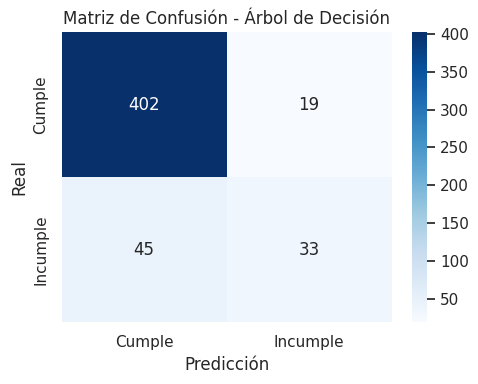

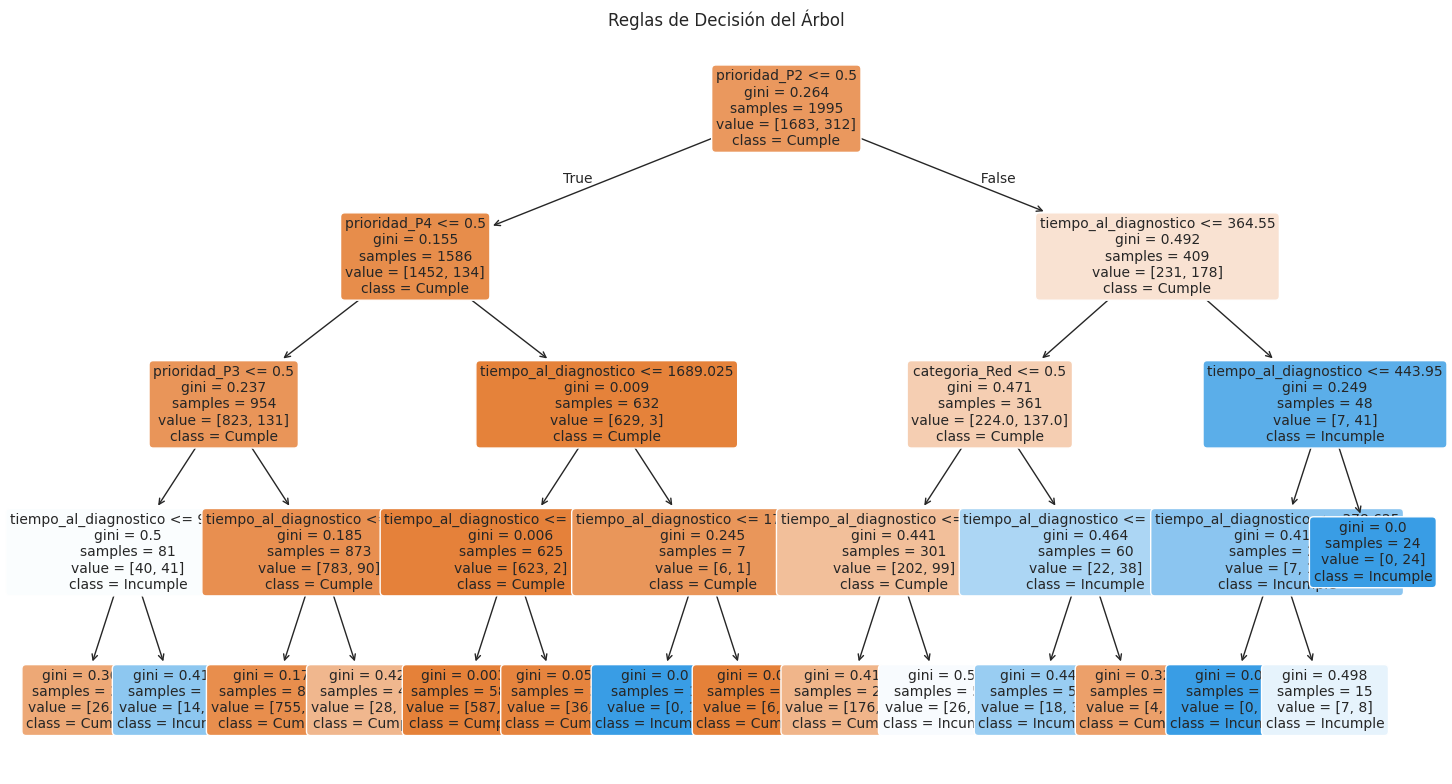

In [12]:
# Para verificar el código corregido, ejecutamos de manera local las instrucciones completas utilizando el intérprete de Python
import sys
sys.path.append('/content/repo/scripts')

# Extraer y ejecutar directamente el código de las celdas del archivo generado para comprobar su correcto funcionamiento
with open('/content/repo/scripts/02_corte3_machine_learning.ipynb', 'r', encoding='utf-8') as f:
    nb = json.load(f)

for cell in nb['cells']:
    if cell['cell_type'] == 'code':
        code_text = "".join(cell['source'])
        # Reemplazar visualizaciones de display en Jupyter para entornos planos
        code_text = code_text.replace("display(", "print(")
        exec(code_text)